# EDA (탐색적 데이터 분석)

목표: 데이터를 눈으로 보고 패턴/이상치/관계를 발견해서, 이후 모델링에 도움이 될 인사이트를 얻는다.

탐색해볼 질문들:
- target(대여량)의 분포는 어떤 모양인가? (정규분포? 치우쳐 있는가? 로그변환이 필요한가?)
- 시간대별 대여량 패턴은? (출퇴근 시간에 몰리는가?)
- 요일별/주말-평일 차이는?
- 계절/월별 패턴은?
- 날씨 변수(기온, 강수량, 습도, 풍속)와 대여량의 관계는?
- 변수들 간 상관관계는 어떤가? (다중공선성 후보가 있는가?)
- 특이하거나 설명이 필요한 패턴이 있는가?
> **누수 방지:** 이 노트북은 02에서 holdout을 떼어 낸 `data/processed/train.csv`만 본다. holdout과 test는 열지 않는다. EDA에서 본 내용은 04의 모델·피처 선택에 영향을 주므로, holdout을 여기서 보면 05의 최종 평가가 낙관적으로 나온다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('../data/processed/train.csv')
WEATHER_COLS = [col for col in train.columns if col.startswith('hour_bef_')]
train.shape

(1165, 12)

## Target 변수 분포


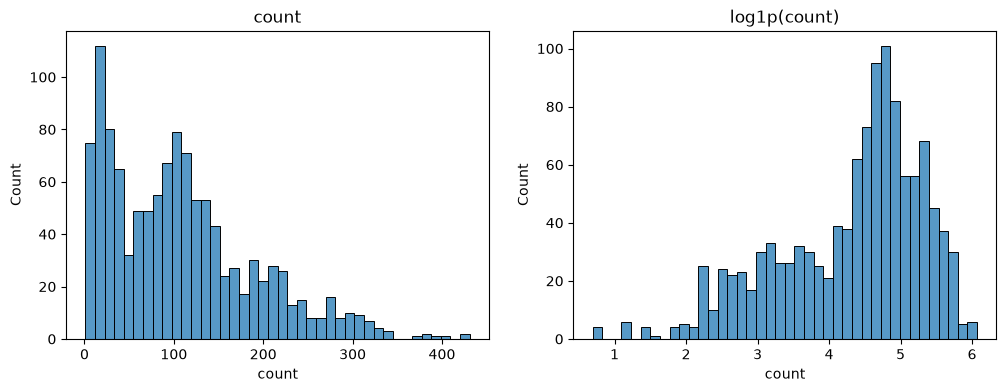

왜도 - 원본: 0.9 / log1p: -0.86


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['count'], bins=40, ax=axes[0]).set_title('count')
sns.histplot(np.log1p(train['count']), bins=40, ax=axes[1]).set_title('log1p(count)')
plt.show()

print('왜도 - 원본:', round(train['count'].skew(), 2), '/ log1p:', round(np.log1p(train['count']).skew(), 2))

## 시간/요일/계절별 패턴


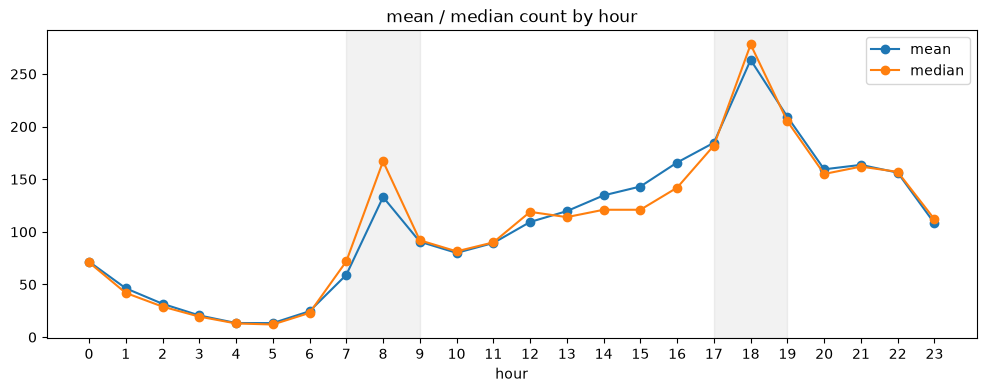

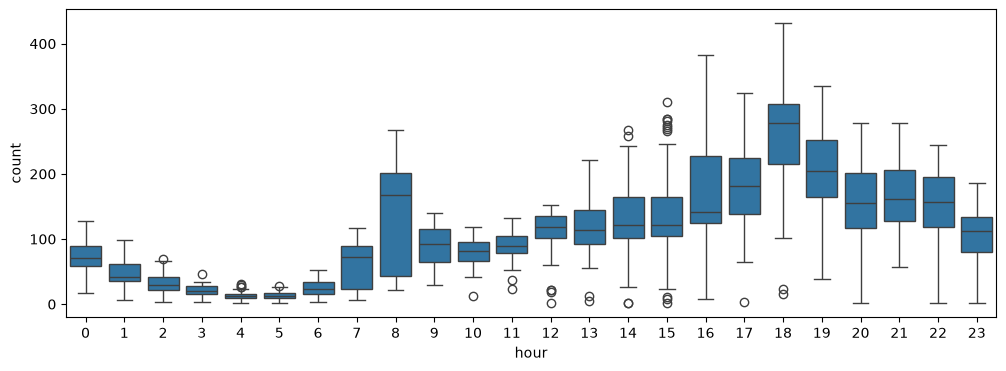

In [3]:
hourly = train.groupby('hour')['count'].agg(['mean', 'median'])
ax = hourly.plot(marker='o', figsize=(12, 4), title='mean / median count by hour')
ax.axvspan(7, 9, alpha=0.1, color='gray')
ax.axvspan(17, 19, alpha=0.1, color='gray')  # 회색: is_peak 구간
ax.set_xticks(range(24))
plt.show()

sns.boxplot(data=train, x='hour', y='count').figure.set_size_inches(12, 4)
plt.show()

8시 행 수: 48 / 60 미만: 18


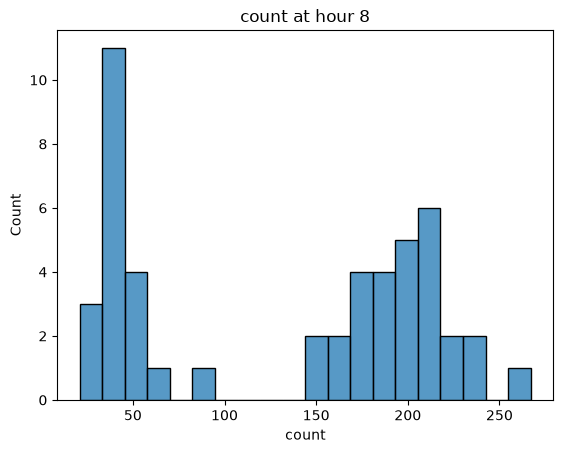

In [4]:
# 8시는 평균(133)이 중앙값(167)보다 훨씬 낮다 → 분포가 두 덩어리로 나뉘는지 확인
at8 = train.loc[train['hour'] == 8, 'count']
print('8시 행 수:', len(at8), '/ 60 미만:', (at8 < 60).sum())
sns.histplot(at8, bins=20).set_title('count at hour 8')
plt.show()

요일·주말/평일·계절·월별 비교는 할 수 없다. 데이터에 날짜 컬럼이 없고, `id`도 시간 순서가 아니다(연속된 id의 시간대가 뒤섞여 있음, 01 참고).

## 날씨 변수와의 관계


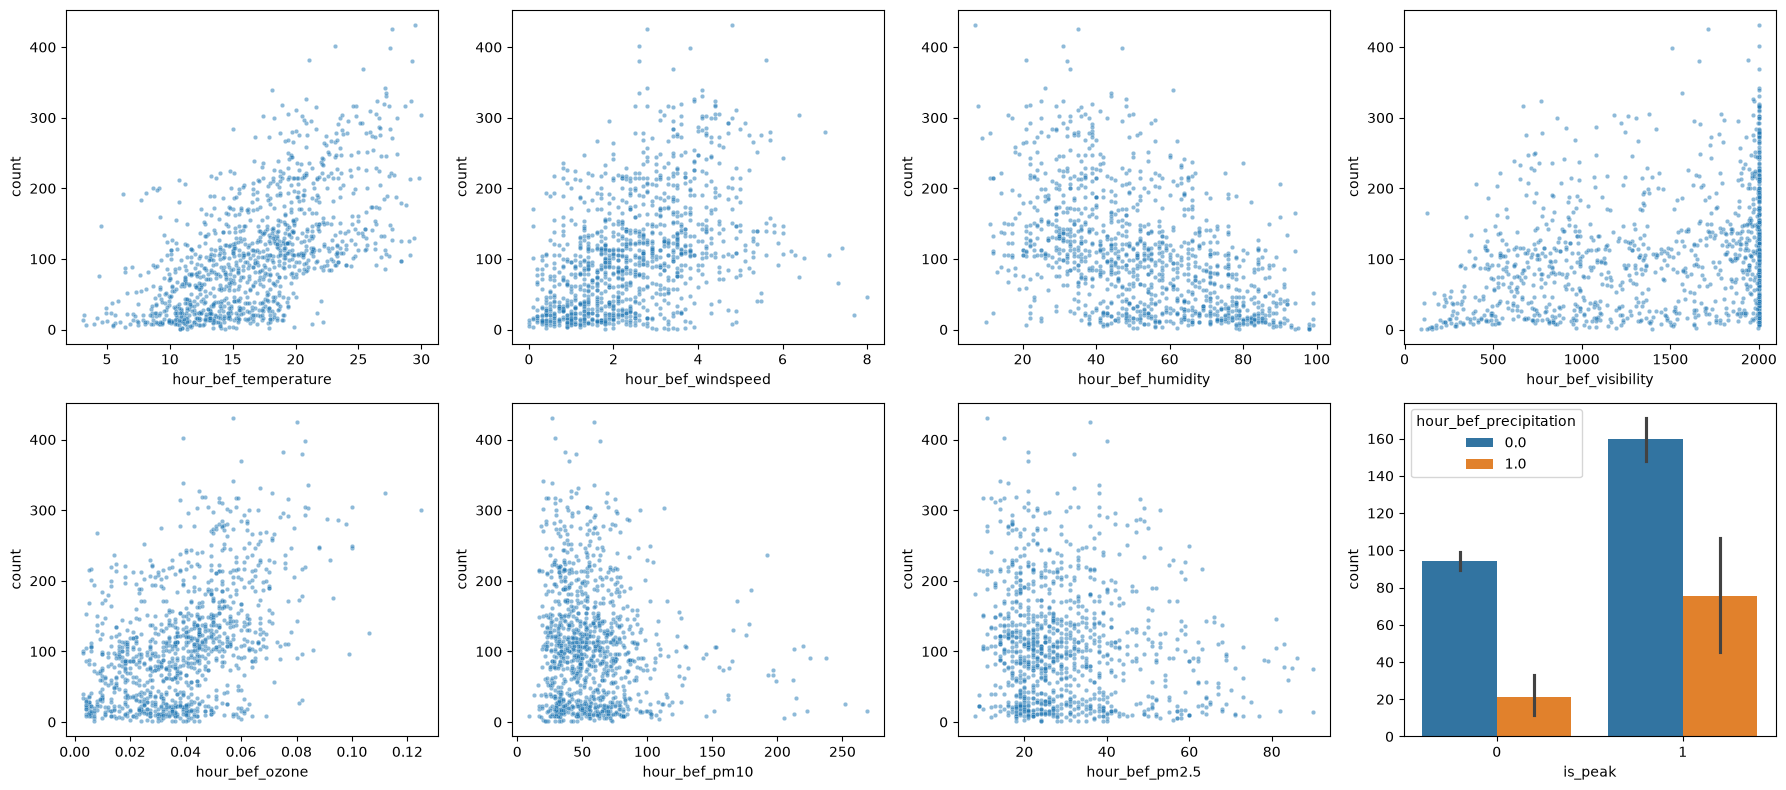

mean  size
is_peak hour_bef_precipitation             
0       0.0                      94.0   847
        1.0                      21.1    28
1       0.0                     159.6   280
        1.0                      75.4    10

In [5]:
cont_cols = [col for col in WEATHER_COLS if col != 'hour_bef_precipitation']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cont_cols):
    sns.scatterplot(data=train, x=col, y='count', s=10, alpha=0.5, ax=ax)

# 강수 여부(0/1)는 출퇴근 시간대 여부와 함께 비교
sns.barplot(data=train, x='is_peak', y='count', hue='hour_bef_precipitation', ax=axes.flat[-1])
plt.tight_layout()
plt.show()

train.groupby(['is_peak', 'hour_bef_precipitation'])['count'].agg(['mean', 'size']).round(1)

In [6]:
# 기온과 시간대는 서로 상관이 있다(낮에 따뜻함). 기온 효과가 시간대 효과를 대신 보여 주는 것인지,
# 같은 시간대 안에서도 기온과 대여량이 관계가 있는지 확인
print('hour vs 기온 상관:', round(train['hour'].corr(train['hour_bef_temperature']), 2))
within = train.groupby('hour').apply(lambda d: d['count'].corr(d['hour_bef_temperature']))
print('같은 시간대 안에서 기온-대여량 상관 (24개 시간대 중앙값):', round(within.median(), 2))
train.groupby(pd.cut(train['hour_bef_temperature'], [0, 10, 15, 20, 25, 35]), observed=True)['count'].mean().round(0)

hour vs 기온 상관: 0.42
같은 시간대 안에서 기온-대여량 상관 (24개 시간대 중앙값): 0.53


hour_bef_temperature
(0, 10]      47.0
(10, 15]     63.0
(15, 20]    109.0
(20, 25]    171.0
(25, 35]    215.0
Name: count, dtype: float64

## 상관관계 분석


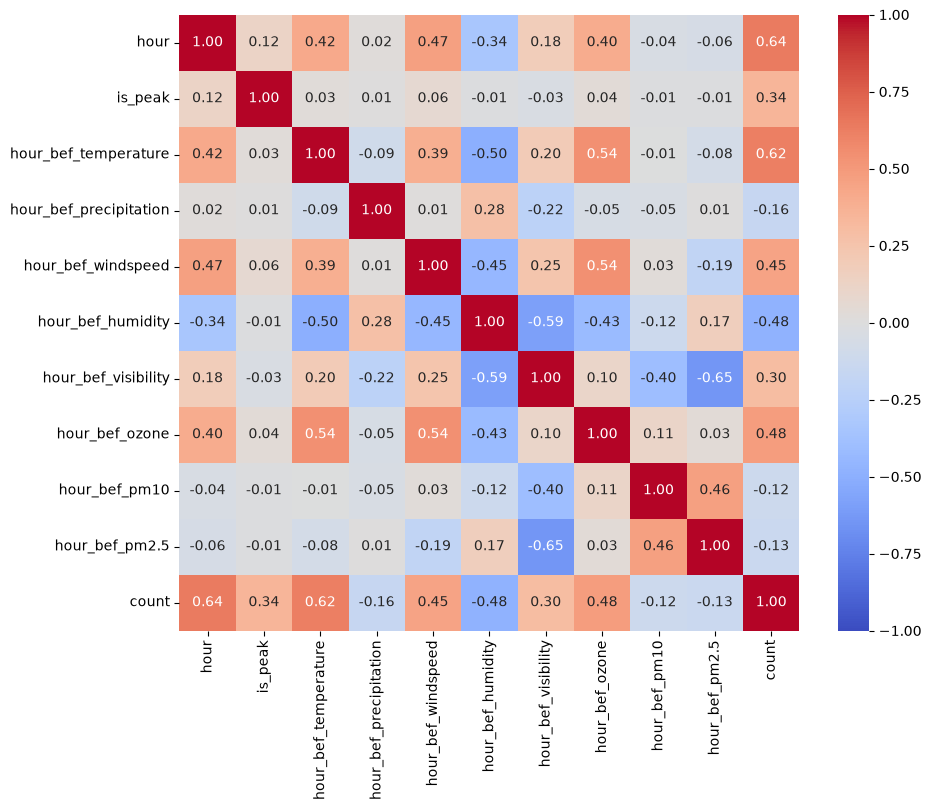

hour_bef_humidity        -0.477391
hour_bef_precipitation   -0.162844
hour_bef_pm2.5           -0.133252
hour_bef_pm10            -0.118456
hour_bef_visibility       0.300353
is_peak                   0.343882
hour_bef_windspeed        0.448010
hour_bef_ozone            0.478900
hour_bef_temperature      0.619647
hour                      0.639443
Name: count, dtype: float64

In [7]:
corr = train[['hour', 'is_peak'] + WEATHER_COLS + ['count']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

corr['count'].drop('count').sort_values()

## 인사이트 정리

모든 수치는 holdout을 뺀 train(1,165행) 기준이다.

1. **target 분포:** 오른쪽으로 치우쳐 있다(왜도 약 0.9). log1p를 취하면 반대로 왼쪽으로 치우친다(약 -0.86). 로그변환이 확실히 낫다고 볼 수 없다. → 04에서 원본과 log1p target을 교차검증으로 비교한다. 평가는 둘 다 원래 단위로 한다.
2. **시간대:** 가장 강한 패턴이다(상관 0.64, 시간대별 평균 13~263). 새벽 4~5시가 가장 적고, 8시에 아침 피크(133)가 뾰족하게 나타난 뒤 9~11시에 다시 줄어든다. 저녁은 18시(263)를 정점으로 16~22시에 넓게 많다. 관계가 직선이 아니다. → 트리 모델은 `hour`를 그대로 쓰고, 선형 모델에는 원핫인코딩이 필요하다.
3. **`is_peak` 정의:** 7시(59)와 9시(91)는 평균(약 109)보다 적고, 20~22시는 피크 구간 밖인데도 많다. 서울시 인센티브 시간대로 정한 `is_peak`는 이 데이터의 실제 피크와 일부만 맞는다. → `hour`가 이미 같은 정보를 더 정확히 담고 있으므로, 04에서 `is_peak`의 유무를 교차검증으로 비교해 쓸지 정한다.
4. **강수:** 비가 오면 대여량이 크게 준다(110 → 35). 출퇴근 시간대에도 160 → 75로 준다. 단, 강수 행이 38개뿐이라 추정이 불안정하다.
5. **기온:** 날씨 변수 중 가장 강하다(상관 0.62). 기온이 높을수록 대여량이 늘고(10℃ 이하 47 → 25℃ 초과 215), 같은 시간대 안에서 봐도 상관이 약 0.53이라 시간대 효과만은 아니다.
6. **시간대와 얽힌 변수:** 습도(-0.48), 오존(0.48), 풍속(0.45)도 상관이 크지만 모두 하루 중 시간에 따라 변하는 변수다(오후에 기온·오존·풍속이 오르고 습도가 내려감). 대여량과의 상관 일부는 시간대 효과가 섞인 것이라, 상관만으로 영향력을 판단하지 않는다. → 05의 feature importance에서 다시 확인한다.
7. **8시 대여량이 두 덩어리로 나뉨:** 8시 48행 중 18행(약 38%)은 60 미만이고 나머지는 대부분 150 이상이다. 출근하는 날과 안 하는 날(주말·공휴일)이 섞인 것으로 보인다. 주말·공휴일은 전체 날짜의 약 30% 이상이라 비율이 비슷하다. 하지만 요일 정보가 없어서 모델이 이 차이를 구분할 수 없다. → 출근 시간대 예측 오차가 클 것으로 예상되며, 05의 오차 분석에서 확인한다.
8. **미세먼지:** pm10·pm2.5와 대여량의 상관은 약하다(약 -0.12).
9. **다중공선성:** 기상 변수끼리 가장 높은 상관이 시정-초미세먼지 0.65 정도라 심각하지 않다. 트리 모델에는 문제가 없고, 선형 모델에서도 변수를 뺄 정도는 아니다.